In [2]:
import torchmetrics
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path
device = "cuda" if torch.cuda.is_available() else "cpu"
TRAIN = True
device


/home/sami/miniconda3/envs/pytorch_course/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


'cuda'

In [2]:

def evaluate_tm(model, data_loader, loss_fn, metric, device):
    model.eval()
    metric.reset()
    total_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch, lengths in data_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch, lengths)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            metric.update(y_pred, y_batch)
    avg_loss = total_loss / len(data_loader)
    return avg_loss, metric.compute()

def train(model, optimizer, loss_fn, metric, train_loader, valid_loader,
          n_epochs, patience=2, factor=0.5, epoch_callback=None, device="cuda", max_grad_norm=1.0):
    model.to(device)
    loss_fn.to(device)
    metric.to(device)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", patience=patience, factor=factor)
    history = {"train_losses": [], "train_metrics": [], "valid_losses": [], "valid_metrics": []}
    model_name = "GRUModel.pt"
    model_path = os.path.join("models", model_name)
    if not os.path.exists("models"):
        os.makedirs("models")
    for epoch in range(n_epochs):
        total_loss = 0.0
        metric.reset()
        model.train()
        if epoch_callback is not None:
            epoch_callback(model, epoch)
        for index, (X_batch, y_batch, lengths) in enumerate(train_loader):
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch, lengths)
            loss = loss_fn(y_pred, y_batch)
            total_loss += loss.item()
            loss.backward()
            # Add gradient clipping to prevent exploding gradients
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()
            optimizer.zero_grad()
            metric.update(y_pred, y_batch)
            train_metric = metric.compute().item()
            print(f"\rBatch {index + 1}/{len(train_loader)}", end="")
            print(f", loss={total_loss/(index+1):.4f}", end="")
            print(f", {train_metric=:.2%}", end="")
        history["train_losses"].append(total_loss / len(train_loader))
        history["train_metrics"].append(train_metric)
        val_loss, val_metric = evaluate_tm(model, valid_loader, loss_fn, metric, device)
        history["valid_losses"].append(val_loss)
        history["valid_metrics"].append(val_metric.item())
        scheduler.step(val_metric)
        if len(history["valid_metrics"]) > 2:
            if history["valid_metrics"][-1] > history["valid_metrics"][-2]:
                torch.save(model, model_path)

        print(f"\rEpoch {epoch + 1}/{n_epochs},                      "
              f"train loss: {history['train_losses'][-1]:.4f}, "
              f"train metric: {history['train_metrics'][-1]:.2%}, "
              f"valid loss: {history['valid_losses'][-1]:.4f}, "
              f"valid metric: {history['valid_metrics'][-1]:.2%}, "
              f"lr: {optimizer.param_groups[0]['lr']:.6f}")
    return history

def register_plot(history):
    plt.figure()
    plt.plot(history["train_losses"], label="Train losses", color="r")
    plt.plot(history["valid_losses"], label="Valid losses", color="darkred")
    plt.plot(history["train_metrics"], label="Train metrics", color="orange")
    plt.plot(history["valid_metrics"], label="Valid metrics", color="g")
    plt.legend()
    plt.grid()
    if not os.path.exists("plots"):
        os.makedirs("plots")
    plt.savefig(os.path.join("plots", "training_plot.png"))


In [8]:


class QuickDrawDataset(Dataset):
    def __init__(self, quickdraw_folder="quickdraw_data", split='train', max_per_class=10000):
        self.data_folder = Path(quickdraw_folder)
        # Exclude .full.npz files to avoid duplicates
        all_files = self.data_folder.glob("*.npz")
        self.files = sorted([f for f in all_files if not f.stem.endswith('.full')])
        self.max_per_class = max_per_class
        self.label_to_idx = {f.stem: i for i, f in enumerate(self.files)}
        
        # Load all data at initialization
        self.data = []
        self.labels = []
        num_files_loaded = 0
        for file_path in self.files:
            label = file_path.stem
            label_idx = self.label_to_idx[label]
            
            # Load all drawings from this file
            data = np.load(file_path, allow_pickle=True, encoding='latin1')
            drawings = data[split]
            num_drawings = min(len(drawings), self.max_per_class)
            
            # Process each drawing
            for drawing_idx in range(num_drawings):
                drawing = drawings[drawing_idx]
                X = torch.tensor(drawing, dtype=torch.float32)
                
                # Pad or truncate to 50 rows
                if X.shape[0] >= 50:
                    X = X[:50]
                else:
                    padding_needed = 50 - X.shape[0]
                    padding = torch.zeros(padding_needed, 3)
                    X = torch.cat([X, padding], dim=0)
                
                self.data.append(X)
                self.labels.append(label_idx)
            num_files_loaded += 1
            print(f"[INFO] {num_files_loaded} / {len(self.label_to_idx)} files laded.")
                
            
            data.close()
        
    
    def __len__(self):
        return len(self.data)
    
    def __getitem__(self, idx):
        X = self.data[idx]
        # Calculate actual length (exclude trailing zero-padding)
        is_padding = (X == 0).all(dim=1)
        length = (~is_padding).sum()
        return X, self.labels[idx], length

In [4]:
train_set = QuickDrawDataset(split='train', max_per_class=15000)
train_loader = DataLoader(dataset=train_set, batch_size=512, shuffle=True, num_workers=2)

/home/sami/miniconda3/envs/pytorch_course/lib/python3.11/site-packages/numpy/lib/_format_impl.py:838: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  array = pickle.load(fp, **pickle_kwargs)


[INFO] 1 / 345 files laded.
[INFO] 2 / 345 files laded.
[INFO] 3 / 345 files laded.
[INFO] 4 / 345 files laded.
[INFO] 5 / 345 files laded.
[INFO] 6 / 345 files laded.
[INFO] 7 / 345 files laded.
[INFO] 8 / 345 files laded.
[INFO] 9 / 345 files laded.
[INFO] 10 / 345 files laded.
[INFO] 11 / 345 files laded.
[INFO] 12 / 345 files laded.
[INFO] 13 / 345 files laded.
[INFO] 14 / 345 files laded.
[INFO] 15 / 345 files laded.
[INFO] 16 / 345 files laded.
[INFO] 17 / 345 files laded.
[INFO] 18 / 345 files laded.
[INFO] 19 / 345 files laded.
[INFO] 20 / 345 files laded.
[INFO] 21 / 345 files laded.
[INFO] 22 / 345 files laded.
[INFO] 23 / 345 files laded.
[INFO] 24 / 345 files laded.
[INFO] 25 / 345 files laded.
[INFO] 26 / 345 files laded.
[INFO] 27 / 345 files laded.
[INFO] 28 / 345 files laded.
[INFO] 29 / 345 files laded.
[INFO] 30 / 345 files laded.
[INFO] 31 / 345 files laded.
[INFO] 32 / 345 files laded.
[INFO] 33 / 345 files laded.
[INFO] 34 / 345 files laded.
[INFO] 35 / 345 files l

In [5]:
val_set = QuickDrawDataset(split='valid', max_per_class=5000)
val_loader = DataLoader(dataset=val_set, batch_size=512, shuffle=True, num_workers=2)

[INFO] 1 / 345 files laded.
[INFO] 2 / 345 files laded.
[INFO] 3 / 345 files laded.
[INFO] 4 / 345 files laded.
[INFO] 5 / 345 files laded.
[INFO] 6 / 345 files laded.
[INFO] 7 / 345 files laded.
[INFO] 8 / 345 files laded.
[INFO] 9 / 345 files laded.
[INFO] 10 / 345 files laded.
[INFO] 11 / 345 files laded.
[INFO] 12 / 345 files laded.
[INFO] 13 / 345 files laded.
[INFO] 14 / 345 files laded.
[INFO] 15 / 345 files laded.
[INFO] 16 / 345 files laded.
[INFO] 17 / 345 files laded.
[INFO] 18 / 345 files laded.
[INFO] 19 / 345 files laded.
[INFO] 20 / 345 files laded.
[INFO] 21 / 345 files laded.
[INFO] 22 / 345 files laded.
[INFO] 23 / 345 files laded.
[INFO] 24 / 345 files laded.
[INFO] 25 / 345 files laded.
[INFO] 26 / 345 files laded.
[INFO] 27 / 345 files laded.
[INFO] 28 / 345 files laded.
[INFO] 29 / 345 files laded.
[INFO] 30 / 345 files laded.
[INFO] 31 / 345 files laded.
[INFO] 32 / 345 files laded.
[INFO] 33 / 345 files laded.
[INFO] 34 / 345 files laded.
[INFO] 35 / 345 files l

In [6]:
X = next(iter(train_loader))[0]

# Find actual sequence lengths (excluding trailing zero-padding)
# A row is padding if all three values are zero
is_padding = (X == 0).all(dim=2)  # Shape: (batch_size, seq_len)
lengths = (~is_padding).sum(dim=1)  # Count non-padding rows
print(pack_padded_sequence(X, lengths, batch_first=True, enforce_sorted=False))

PackedSequence(data=tensor([[-10., -12.,   0.],
        [ 26.,  12.,   0.],
        [-13.,   1.,   0.],
        ...,
        [ -7.,  11.,   0.],
        [ 52.,  19.,   0.],
        [  0., -10.,   0.]]), batch_sizes=tensor([512, 512, 512, 511, 511, 509, 509, 509, 509, 509, 507, 506, 505, 504,
        499, 497, 495, 491, 486, 478, 472, 464, 457, 451, 446, 433, 428, 420,
        416, 409, 399, 392, 380, 367, 356, 349, 337, 327, 320, 312, 297, 288,
        277, 268, 261, 255, 249, 241, 234, 218]), sorted_indices=tensor([273, 143, 461, 460, 459, 278, 148, 149, 150, 276, 152, 275, 154, 386,
        279, 157, 158, 272, 270, 453, 391, 268, 164, 394, 395, 167, 168, 452,
        128, 295, 114, 377, 117, 291, 119, 120, 471, 289, 288, 125, 126, 382,
        396, 129, 383, 131, 132, 283, 282, 135, 385, 137, 138, 139, 280, 463,
        413, 244, 242, 241, 409, 424, 423, 205, 235, 412, 420, 209, 419, 211,
        198, 231, 230, 215, 418, 229, 227, 219, 220, 221, 222, 226, 224, 225,
        439, 257, 

In [5]:
class GRUModel(nn.Module):

    def __init__(self, hidden_size=128, n_outputs = 345, *args, **kwargs):
        super().__init__(*args, **kwargs)

        # seq shape: N, 33, 3
        self.embedder = nn.Sequential(
            nn.Linear(3, 64),
            nn.ReLU()
        )
        # X shape: N, 33, 64
        self.gru = nn.GRU(
            64,
            hidden_size= hidden_size,
            num_layers=3,
            batch_first=True,
            dropout=0.2,
            bidirectional=False
        )
        # h_ns[-1] shape: N, hidden_size
        self.fc = nn.Linear(hidden_size, n_outputs)
        # output shape = N, n_outputs


    def forward(self, seq, lengths=None):
        # Embed the input
        X = self.embedder(seq)
        
        if lengths is not None:
            X_packed = pack_padded_sequence(X, lengths.cpu(), batch_first=True, enforce_sorted=False)
            output_packed, h_ns = self.gru(X_packed)
        else:
            output_, h_ns = self.gru(X)
        
        return self.fc(h_ns[-1])

Epoch 1/50,                      train loss: 3.1660, train metric: 30.89%, valid loss: 2.1752, valid metric: 47.54%, lr: 0.000100
Epoch 2/50,                      train loss: 1.9205, train metric: 52.81%, valid loss: 1.6826, valid metric: 57.80%, lr: 0.000100
Epoch 3/50,                      train loss: 1.6137, train metric: 59.28%, valid loss: 1.4882, valid metric: 62.05%, lr: 0.000100
Epoch 4/50,                      train loss: 1.4566, train metric: 62.70%, valid loss: 1.3773, valid metric: 64.56%, lr: 0.000100
Epoch 5/50,                      train loss: 1.3572, train metric: 64.92%, valid loss: 1.2969, valid metric: 66.37%, lr: 0.000100
Epoch 6/50,                      train loss: 1.2906, train metric: 66.43%, valid loss: 1.2530, valid metric: 67.38%, lr: 0.000100
Epoch 7/50,                      train loss: 1.2424, train metric: 67.49%, valid loss: 1.2095, valid metric: 68.38%, lr: 0.000100
Epoch 8/50,                      train loss: 1.2046, train metric: 68.35%, valid loss: 1.1

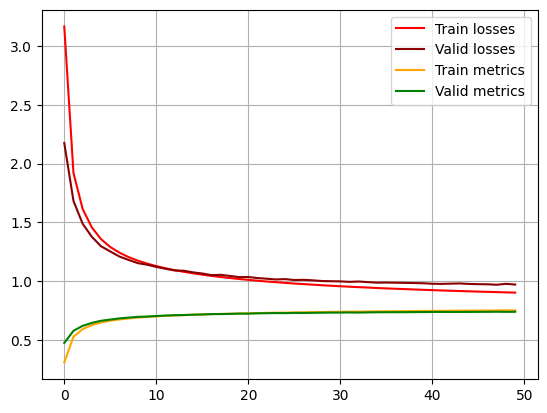

In [8]:
if TRAIN:
    n_epochs = 50
    N_CATS = 345
    model = GRUModel(hidden_size=256, n_outputs=N_CATS)
    optimizer = torch.optim.NAdam(model.parameters(), lr=0.0001)  # Reduced learning rate
    loss_fn = nn.CrossEntropyLoss()
    metric = torchmetrics.Accuracy(task='multiclass', num_classes=N_CATS)
    history = train(model, optimizer, loss_fn, metric, train_loader, val_loader, 
                    n_epochs, patience=5, factor=0.5, max_grad_norm=1.0)  # Increased patience, added gradient clipping
    register_plot(history)


In [9]:
# TEST the model
test_set = QuickDrawDataset(split='test', max_per_class=10000)
test_loader = DataLoader(dataset=test_set, batch_size=256, shuffle=True, num_workers=4)



/home/sami/miniconda3/envs/pytorch_course/lib/python3.11/site-packages/numpy/lib/_format_impl.py:838: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  array = pickle.load(fp, **pickle_kwargs)


[INFO] 1 / 345 files laded.
[INFO] 2 / 345 files laded.
[INFO] 3 / 345 files laded.
[INFO] 4 / 345 files laded.
[INFO] 5 / 345 files laded.
[INFO] 6 / 345 files laded.
[INFO] 7 / 345 files laded.
[INFO] 8 / 345 files laded.
[INFO] 9 / 345 files laded.
[INFO] 10 / 345 files laded.
[INFO] 11 / 345 files laded.
[INFO] 12 / 345 files laded.
[INFO] 13 / 345 files laded.
[INFO] 14 / 345 files laded.
[INFO] 15 / 345 files laded.
[INFO] 16 / 345 files laded.
[INFO] 17 / 345 files laded.
[INFO] 18 / 345 files laded.
[INFO] 19 / 345 files laded.
[INFO] 20 / 345 files laded.
[INFO] 21 / 345 files laded.
[INFO] 22 / 345 files laded.
[INFO] 23 / 345 files laded.
[INFO] 24 / 345 files laded.
[INFO] 25 / 345 files laded.
[INFO] 26 / 345 files laded.
[INFO] 27 / 345 files laded.
[INFO] 28 / 345 files laded.
[INFO] 29 / 345 files laded.
[INFO] 30 / 345 files laded.
[INFO] 31 / 345 files laded.
[INFO] 32 / 345 files laded.
[INFO] 33 / 345 files laded.
[INFO] 34 / 345 files laded.
[INFO] 35 / 345 files l

In [10]:
model = torch.load(os.path.join("models", "GRUModel.pt"), weights_only=False)
X, y, padding = next(iter(test_loader))
print(y)
model.eval()
with torch.no_grad():  
    y_pred = model(X.to(device))
print(y_pred.shape)
pred_cats = torch.argmax(y_pred, dim = 1)
diff = pred_cats - y.to(device)
print(diff)

tensor([322, 221, 156, 276, 106,  11, 114,  24,  69, 115,  70,   4, 295, 275,
        162, 220, 257, 224, 197, 272,  82,   5,  28,  21, 224, 287,  43,  46,
         36, 255, 137, 122, 192, 129, 324, 278,  39, 167, 329,  69, 269, 116,
        278, 231, 331, 261, 333,  28,  86, 196, 299, 108, 167, 298,  94,  89,
         45,  22, 130, 185,  68, 265, 300, 135, 112, 307, 231, 291, 280, 151,
        279, 156, 296,  15, 140,  42,   5, 269,   9,  62, 108,  21, 126, 241,
        322, 210, 125, 323, 294, 340, 148, 282,  41,  18, 242,  39, 240, 322,
        228, 177, 157,  26, 158, 312, 177, 294, 233, 301, 114, 173, 108,  94,
        233, 291, 331,  50, 191, 154, 302, 232, 119, 201, 313, 137, 203, 193,
        252, 146, 234, 324, 252,  79,  44, 135,  39, 327, 344,  30, 334,  97,
        270,  87, 291, 158,  78, 227, 216, 299, 281, 145, 128,   8,  66, 309,
         38, 117, 322, 185,   6, 218,  77, 288, 206, 150, 312, 229, 308,  96,
        235, 336, 155,  37, 259,  80, 338,   0, 126, 252, 307, 2